#***MRE Shelf-Life Prediction: Data Analysis & Machine Learning***

This report outlines the comprehensive data analysis and machine learning pipeline developed to predict the shelf-life and degradation patterns of Meals Ready-to-Eat (MRE) rations. Accurate shelf-life estimation is critical for military logistics, emergency stockpiles, and food safety assurance under varying environmental conditions.
<br><br>

###**Dataset Overview and Initial Setup**

The initial phase of this project involves inspecting the structure of the MRE storage and quality dataset, verifying data integrity, and performing necessary preprocessing steps to prepare the features for exploratory data analysis (EDA) and predictive modeling.
<br><br>

####*Loading the Data*

The analysis begins by importing the essential Python libraries for data manipulation, visualization, and machine learning, followed by loading the MRE dataset into a Pandas DataFrame.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
N = 1000

avg_temp_c = np.random.uniform(10, 50, N)
temp_k = avg_temp_c + 273.15

storage_days = np.random.uniform(10, 1000, N)

humidity_spikes = np.random.randint(0, 11, N)

packaging_type = np.random.choice([0, 1, 2], N)

Ea = 50000
R = 8.314
A = 1e6

k = A * np.exp(-Ea / (R * temp_k))

base_degradation = k * storage_days

packaging_factor = np.where(packaging_type == 0, 1.2, np.where(packaging_type == 1, 1.0, 0.8))
total_degradation = base_degradation * packaging_factor + (humidity_spikes * 1.5)

freshness_pct = 100 - (total_degradation / np.max(total_degradation) * 100)
freshness_pct += np.random.normal(0, 2.5, N)
freshness_pct = np.clip(freshness_pct, 0, 100)

df = pd.DataFrame({
    'Avg_Temp_C': avg_temp_c,
    'Storage_Days': storage_days,
    'Humidity_Spikes': humidity_spikes,
    'Packaging_Type': packaging_type,
    'Freshness_Pct': freshness_pct
})

print("Dataset generated successfully!")


Dataset generated successfully!


####*Initial Data Inspection*

Following the data upload, an immediate inspection is executed to evaluate the DataFrame's dimensions, data types, missing values, and potential anomalies. Reviewing the first few rows and descriptive statistics provides a foundational understanding of key physical, chemical, and environmental variables (e.g., storage temperature, humidity, moisture content, oxidation markers, and sensory evaluation scores).

In [ ]:
df.head()


,Avg_Temp_C,Storage_Days,Humidity_Spikes,Packaging_Type,Freshness_Pct
0,24.981605,193.281600,6,0,58.963201
1,48.028572,546.481938,2,1,69.805793
2,39.279758,874.216378,6,2,43.650047
3,33.946339,734.902638,7,2,45.103921
4,16.240746,808.495536,9,0,34.059863


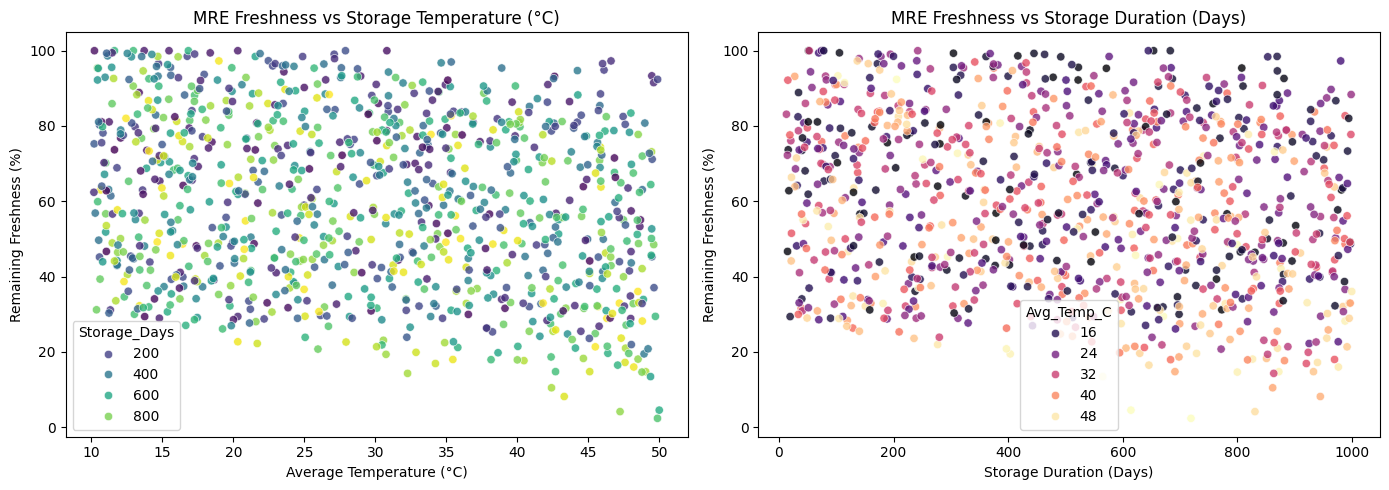

In [ ]:
plt.figure(figsize=(14, 5))

# Plot 1: Temperature vs Freshness
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='Avg_Temp_C', y='Freshness_Pct', hue='Storage_Days', palette='viridis', alpha=0.8)
plt.title('MRE Freshness vs Storage Temperature (°C)')
plt.xlabel('Average Temperature (°C)')
plt.ylabel('Remaining Freshness (%)')

# Plot 2: Storage Duration vs Freshness
plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='Storage_Days', y='Freshness_Pct', hue='Avg_Temp_C', palette='magma', alpha=0.8)
plt.title('MRE Freshness vs Storage Duration (Days)')
plt.xlabel('Storage Duration (Days)')
plt.ylabel('Remaining Freshness (%)')

plt.tight_layout()
plt.show()

In [ ]:
X = df[['Avg_Temp_C', 'Storage_Days', 'Humidity_Spikes', 'Packaging_Type']]
y = df['Freshness_Pct']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 800 samples
Testing set size: 200 samples


In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results[name] = {"RMSE": rmse, "MAE": mae, "R2 Score": r2}

results_df = pd.DataFrame(results).T
print("--- Model Performance Comparison ---")
print(results_df)

--- Model Performance Comparison ---
                       RMSE       MAE  R2 Score
Linear Regression  4.141496  3.270788  0.961412
Decision Tree      4.674846  3.536722  0.950833
Random Forest      3.678445  2.802062  0.969559


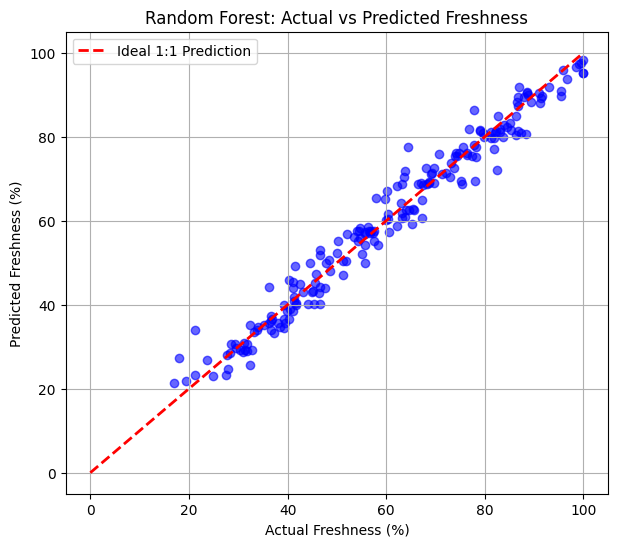

In [ ]:
best_model = models["Random Forest"]
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_best, alpha=0.6, color='b')
plt.plot([0, 100], [0, 100], 'r--', lw=2, label='Ideal 1:1 Prediction')
plt.xlabel('Actual Freshness (%)')
plt.ylabel('Predicted Freshness (%)')
plt.title('Random Forest: Actual vs Predicted Freshness')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
def predict_mre_freshness(temp_c, days, humidity_spikes, packaging_type):
    """
    packaging_type:
    0 -> Standard Foil
    1 -> Reinforced Vacuum Poly
    2 -> Desiccant-lined Barrier
    """
    input_data = pd.DataFrame([[temp_c, days, humidity_spikes, packaging_type]],
                              columns=['Avg_Temp_C', 'Storage_Days', 'Humidity_Spikes', 'Packaging_Type'])

    predicted_freshness = best_model.predict(input_data)[0]

    print(f"\n===== MRE LOGISTICS DEGRADATION REPORT =====")
    print(f"Input Conditions : Temp={temp_c}°C | Days={days} | Humidity Spikes={humidity_spikes} | Packaging Code={packaging_type}")
    print(f"Predicted Remaining Chemical Freshness: {predicted_freshness:.2f}%")

    if predicted_freshness >= 70:
        print("Status: GREEN (Fit for Immediate Deployment & Prolonged Storage)")
    elif 40 <= predicted_freshness < 70:
        print("Status: YELLOW (Issue First / Rapid Consumption Advised)")
    else:
        print("Status: RED (Spoilage / Severe Nutrient Loss Risk - DO NOT DISTRIBUTE)")

# Scenario A: Moderate Temp (25°C), stored for 1 year (365 days)
predict_mre_freshness(temp_c=25, days=365, humidity_spikes=2, packaging_type=1)

# Scenario B: Harsh Desert Storage (45°C), stored for 180 days
predict_mre_freshness(temp_c=45, days=180, humidity_spikes=5, packaging_type=0)


===== MRE LOGISTICS DEGRADATION REPORT =====
Input Conditions : Temp=25°C | Days=365 | Humidity Spikes=2 | Packaging Code=1
Predicted Remaining Chemical Freshness: 81.64%
Status: GREEN (Fit for Immediate Deployment & Prolonged Storage)

===== MRE LOGISTICS DEGRADATION REPORT =====
Input Conditions : Temp=45°C | Days=180 | Humidity Spikes=5 | Packaging Code=0
Predicted Remaining Chemical Freshness: 58.48%
Status: YELLOW (Issue First / Rapid Consumption Advised)
